Simulating hodgkin huxley neurons in C++
This is just a quick bit of testing, but may provide a base for an improved version of the simulator

Basic features:
Single compartment conductance based neurons
Voltage and ligand gating 
Simple conductance based synapses

Conductance based neurons:
Resting membrane potential defined in terms of membrane conductances for each ion # Nernst potentials for Na, K, Cl, and Ca, and 
Monoexponential gating defined in terms of Vhalf, Vk, theta0 theta1 sig0 k0



Extra features:
Multicompartments
ChatGPT compile python to c++
Delays
Gap junctions 
Short term plasticity
Long term calcium based plasticity 

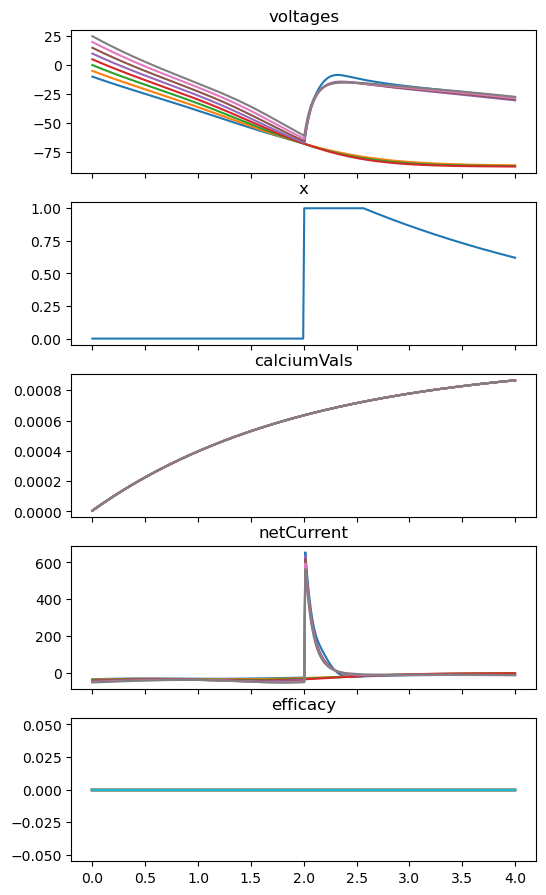

In [1]:
from auxillaryFunctions import *

# build_dir,configType = "build", "Debug"
# moduleDir = os.path.join(build_dir, configType)
# if moduleDir not in sys.path:
#     sys.path.append(moduleDir)

# import cathalTest

#need to map gates to ion channels to neurons
#although if we assume 2 gates per neuron, we can just map gates to neuron 

#we use inverse slope, 1/k, whereas most of the literature uses k. This is because we want to avoid division in the sigmoid function
def genGate(vHalf,vKi,tau0,tau1,th,tkInv,x0=0.0,exponent=1,minOpenness=0):
    return {"x":x0, "vHalf":vHalf,"vKi":vKi,"tau0":tau0,"tau1":tau1,"th":th,"tkInv":tkInv,"exponent":exponent,"minOpenness":minOpenness}

def genOpenGate():
    return genGate(-1000,1000,100,1000,0,0,x0=1)

# gate1 = genGate(-40,2,10,20,-45,10)
# gate2 = genGate(-35,-2,1,10,-45,10)

# ionChannelTypes = {"Ion":0,
#                    "Ca":1,
#                    }
Nav1x6 = {"name":"Nav1x6",
            "ion":"Na",
           "Erev": 90,
           "conductance": 40,
           "CaCurrent": 0, #its not a Ca current, this is just for testing (although, many cation channels will let in a tiny bit of Ca)
           "gates":{
           "vGate1":genGate(-40,-1/4,0.2,2,-20,-1/5,exponent=3,minOpenness=0.0), #inactivation, slow to fast
           "vGate2":genGate(-30,1/4,0.1,0.1,-1000,100), #activation , slow to fast 
           "CaGate":genOpenGate(),
           "spikeGate":genOpenGate()}}


Kv2x1 = {"name":"Kv2x1",
        "ion":"K",
           "Erev": -90,
           "conductance": 20,
           "CaCurrent": 0,
           "gates":{
           "vGate1":genGate(-20,-1/10,1,45,-46,1/44,exponent=4),
           "vGate2":genOpenGate(),
           "CaGate":genOpenGate(),
           "spikeGate":genOpenGate()}}

Kv2x2 = {"name":"Kv2x2",
        "ion":"K",
           "Erev": -90,
           "conductance": 20,
           "CaCurrent": 0,
           "gates":{
           "vGate1":genGate(-30,1/10,1,5,-20,-1/10,exponent=1),
           "vGate2":genGate(-30,-1/10,1,5,-46,1/20,exponent=1),
           "CaGate":genOpenGate(),
           "spikeGate":genOpenGate()}}

Kv3x1 = {"name":"Kv3x1",
        "ion":"K",
           "Erev": -90,
           "conductance": 4,
           "CaCurrent": 0,
           "gates":{
           "vGate1":genGate(-10,-1/8,1,5,-8,1/10,exponent=4,minOpenness=0.0),
           "vGate2":genOpenGate(),
           "CaGate":genOpenGate(),
           "spikeGate":genOpenGate()}}

leakChannel = {"name":"leak",
            "ion":"all",
           "Erev": -75,
           "conductance": 0.5,
           "current":0,
           "CaCurrent": 0,
           "gates":{
           "vGate1":genOpenGate(),
           "vGate2":genOpenGate(),
           "CaGate":genOpenGate(),
           "spikeGate":genOpenGate()}}

def genSynapseGate(xt1,TS):
    xt0 = TS
    xt1 = xt1-xt0
    return genGate(0.5,100,xt0,xt1,0.5,-100)


def genDefaultPlasticSynapseData(gain):
    return {
        "efficacy": 0, #p, unitless
        "conductanceGain": gain, #
        "rate": 0.05, #ms
        "gammaP": 0.12, #p per ms
        "gammaD": 0.078, #p per ms
        "thetaP": 0.68, #Ca mol/L
        "thetaD": 0.33, #Ca mol/L
    }

def genAMPA(TS):
    #for the synapses to work properly you need to know TS
    #This lets the conductance go instantly from 0 to 1
    #I wonder if this will cause instability?
    #If this doesnt work I'll have to implement a more expensive second order ODE
    gain = 10
    AMPA = {"name":"AMPAR",
                "ion":"Cation",
            "Erev": 0,
            "conductance": gain,
            "current":0,
            "CaCurrent": 0,
            "gates":{
            "vGate1":genOpenGate(),
            "vGate2":genOpenGate(),
            "CaGate":genOpenGate(),
            "spikeGate":genSynapseGate(3,TS)}}
    for key,val in genDefaultPlasticSynapseData(gain).items():
        AMPA[key] = val
    return AMPA


    
def addBasicChannelToSystem(allChannelData,neuronId,channelInfo):
    #This is the minimum base function for adding a channel-like mechanism to the system
    allChannelData["nChannels"]+=1  #not sure if i should do this at the start or end, probably doesnt matter
    allChannelData["postNeuron"].append(neuronId)
    allChannelData["preNeuron"].append(neuronId)
    zeroKeys = ["efficacy","conductanceGain","rate","gammaP","gammaD","thetaP","thetaD"]
    for key in zeroKeys:
        allChannelData[key].append(0)

    gates = channelInfo["gates"]
    gateSubKeys = gates[list(gates.keys())[0]].keys()
    #pull out the data into a list
    data = {gsk: [gv[gsk] for gv in gates.values()] for gsk in gateSubKeys}
    for key,newData in data.items():
        allChannelData[key].append(newData)

    allChannelData["Erev"].append(channelInfo["Erev"])
    allChannelData["conductance"].append(channelInfo["conductance"])
    allChannelData["CaCurrent"].append(channelInfo["CaCurrent"])
    allChannelData["inputDelay"].append(0)

def addSynapseToSystem(preNeuron,postNeuron,synapseInfo,delayInt,allChannelData):
    addBasicChannelToSystem(allChannelData,preNeuron,synapseInfo)
    allChannelData["postNeuron"][-1] = postNeuron 
    allChannelData["inputDelay"][-1] = delayInt
    allChannelData["efficacy"][-1] = 0 #p, unitless
    allChannelData["conductanceGain"][-1] = synapseInfo["conductanceGain"] if "conductanceGain" in synapseInfo.keys() else 0
    allChannelData["rate"][-1] = synapseInfo["rate"] if "rate" in synapseInfo.keys() else 0 #ms
    allChannelData["gammaP"][-1] = synapseInfo["gammaP"] if "gammaP" in synapseInfo.keys() else 0#p per ms
    allChannelData["gammaD"][-1] = synapseInfo["gammaD"] if "gammaD" in synapseInfo.keys() else 0#p per ms
    allChannelData["thetaP"][-1] = synapseInfo["thetaP"] if "thetaP" in synapseInfo.keys() else 0 #Ca mol/L
    allChannelData["thetaD"][-1] = synapseInfo["thetaD"] if "thetaD" in synapseInfo.keys() else 0 #Ca mol/L
    

def genChannelData(nNeurons,edgeList,diffusionList,TS):
    allChannelData = {key:[] for key in genOpenGate().keys()}
    listKeys = ["postNeuron","preNeuron","conductance","Erev","CaCurrent","inputDelay", #channel parameters
                "efficacy","conductanceGain","rate","gammaP","gammaD","thetaP","thetaD", #plasticity parameters
                "diffPostNeuron","diffPreNeuron","diffRate",] #diffusion parameters
    valueKeys = ["nChannels","nDiffusiveConnections"]

    for key in listKeys:
        allChannelData[key] = []
    for key in valueKeys:
        allChannelData[key] = 0

    #efficacy, conductanceGain, rate, gammaP, gammaD, thetaP, thetaD,
    def addDiffusiveConnection(preNeuron,postNeuron,diffusionRate):
        allChannelData["diffPostNeuron"].append(postNeuron)
        allChannelData["diffPreNeuron"].append(preNeuron)
        allChannelData["diffRate"].append(diffusionRate)
        allChannelData["nDiffusiveConnections"]+=1

    allChannelData["nNeurons"] = nNeurons   
    for i in range(nNeurons):
        addBasicChannelToSystem(allChannelData,i,leakChannel)
        addBasicChannelToSystem(allChannelData,i,Nav1x6,)
        #addBasicChannelToSystem(allChannelData,i,Kv2x1,)
        addBasicChannelToSystem(allChannelData,i,Kv2x2,)

    allChannelData["writeIndex"] = np.zeros(nNeurons,dtype=np.int32)
    maxDelayInt = 1 #default to 1
    for (e0,e1) in edgeList:
        delay = 2 #ms
        delayInt = int(np.ceil(delay/TS))
        assert e0<nNeurons and e1<nNeurons, f"edge out of range {e0},{e1}"
        addSynapseToSystem(e0,e1,genAMPA(TS),delayInt,allChannelData)
        maxDelayInt = max(delayInt,maxDelayInt)

    for (e0,e1,diffusionRate) in diffusionList:
        assert e0<nNeurons and e1<nNeurons, f"edge out of range {e0},{e1}"
        addDiffusiveConnection(e0,e1,diffusionRate)
    
    allChannelData["maxDelayInt"] = maxDelayInt
    allChannelData["voltages"] = -10*np.ones(nNeurons,dtype = np.float32) + 5*np.arange(0,nNeurons,dtype=np.float32)
    allChannelData["calciumVals"] = np.zeros(nNeurons,dtype = np.float32)
    allChannelData["spikeVals"] = np.zeros(nNeurons,dtype = np.float32)
    allChannelData["netCurrent"] = np.zeros(nNeurons,dtype = np.float32)
    allChannelData["netCaCurrent"] = np.zeros(nNeurons,dtype = np.float32)
    allChannelData["spikeBuffer"] = np.zeros((nNeurons,maxDelayInt),dtype=bool)

    intKeys = ["preNeuron","postNeuron", "nChannels","diffPostNeuron",
               "diffPreNeuron","nDiffusiveConnections","writeIndex",
               "maxDelayInt","inputDelay","nNeurons"]
    nonArrayKeys = ["nNeurons","maxDelayInt","nChannels","nDiffusiveConnections"]
    for key in allChannelData.keys():
        val = allChannelData[key]
        if key in intKeys: arrDtype = np.int32
        else: arrDtype = np.float32

        if type(val) in [list,tuple]:
            allChannelData[key] = np.ascontiguousarray(val,dtype = arrDtype)
        elif type(val)  == np.ndarray:
            allChannelData[key] = np.ascontiguousarray(val,dtype = val.dtype)
        elif key in nonArrayKeys:
            pass
        else:
            print(f"Warning {key} is not a list or tuple") 
    
    return allChannelData


build_dir,configType = "build", "Debug"
moduleDir = os.path.join(build_dir, configType)
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest
def solveSystemCpp(ac,TS,runTime,recordingKeys = ["voltages","x","calciumVals","netCurrent","efficacy"]):
    nIterations = int(runTime/TS)
    data = {key:[] for key in recordingKeys}
    tv = np.linspace(0,runTime,nIterations)
    for i in range(nIterations):
        cathalTest.solveNeuralSystem(ac,1,TS)
        for key in data:
            data[key].append(deepcopy(ac[key]))

    for key in data:
        data[key] = np.array(data[key])
    data["time"] = tv
    return data


runTime = 4
TS = 0.01
nNeurons = 8

edgeList = [[1,2],[3,4],[4,5],[5,6],[6,7],[7,0]]
diffRate = 1.0
diffusionList = [(0,1,diffRate),(2,3,diffRate)]
diffusionList = []

allChannelDataPy = genChannelData(nNeurons,edgeList,diffusionList,TS)
allChannelDataCpp = deepcopy(allChannelDataPy)
stimTime = 5
stimInd = int(stimTime/TS)
#stimInfo = {stimInd:[allChannelDataPy["nChannels"]-1]}
stimInfo = {}
#allChannelDataCpp = genChannelData(nNeurons,edgeList,TS)
data = solveSystemStandard(allChannelDataPy,TS,runTime,stimInfo)
standardPlot(data)

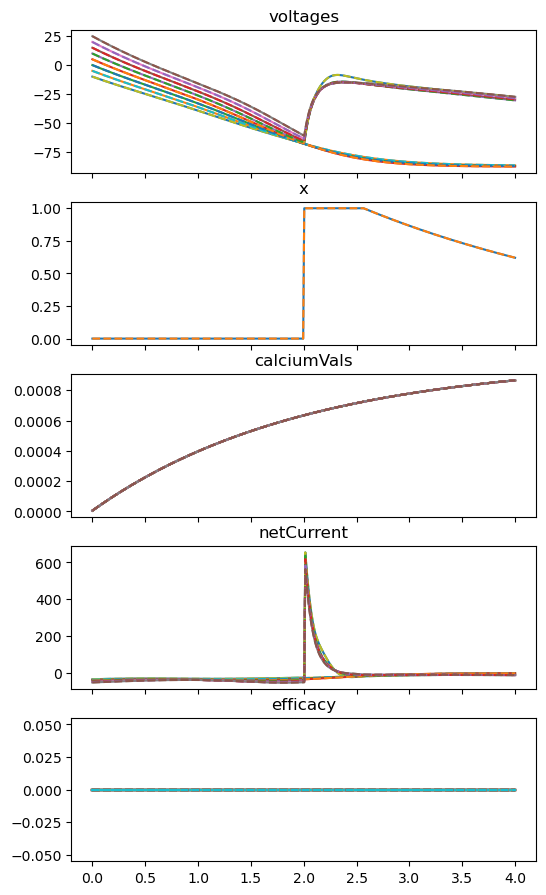

In [2]:
def gatingPlot(data,ax=None):
    time = data["time"]
    gatingData = data["x"]
    nChannels = gatingData.shape[1]
    nGates = gatingData.shape[2]
    if ax is None:
        fig,ax = plt.subplots(nChannels,nGates,figsize = (12,2.5*nChannels),dpi=120,sharex=True,sharey=True)

    if len(ax.shape) ==1:
        ax = np.array([ax,ax])
    for i in range(nChannels):
        for j in range(nGates):
            ax[i,j].plot(time,gatingData[:,i,j])
            ax[i,j].set_title(f"{i},{j}")

    return ax

def gatingPlotSideBySide(data1,data2):
#fig,ax = plt.subplots(nChannels,nGates,figsize = (12,1.8*nChannels),dpi=120,sharex=True,sharey=True)
    ax = gatingPlot(data1,None)   
    gatingPlot(data2,ax)


allChannelDataPy = genChannelData(nNeurons,edgeList,diffusionList,TS)
allChannelDataCpp = deepcopy(allChannelDataPy)
#currently 20x worse than realtime, 500ms takes 10s
dataCpp = solveSystemCpp(allChannelDataCpp,TS,runTime)
#gatingPlotSideBySide(data,dataCpp)
sideBySidePlot(data,dataCpp)

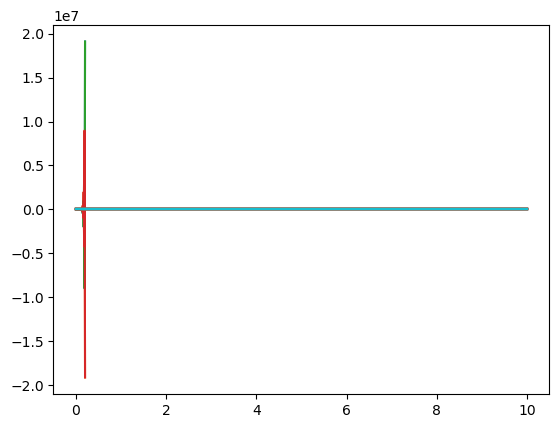

In [5]:
plt.figure()
plt.plot(cTv,cVs);

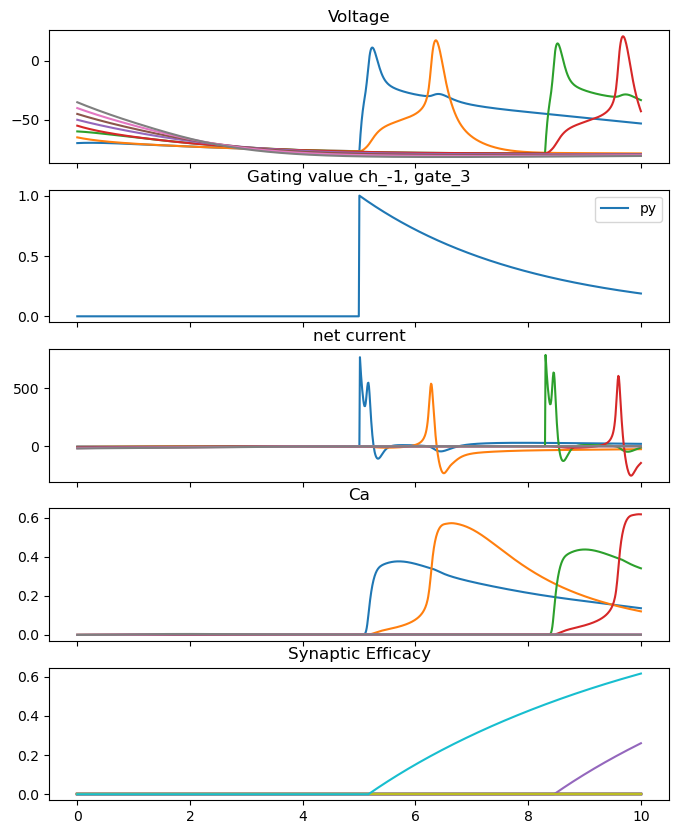

In [12]:
#vDataCpp,gateDataCpp,netCurrentCpp = solveSystemCpp(nNeurons,allChannelDataCpp,TS,runTime)


standardPlot(data)

In [112]:
def calcWeightChange(p,Ca,rate,gammaP,gammaD,thetaP,thetaD):
    #from the Graupner and Brunel paper
    #rate = 1/tau 
    pStar = 0.5
    revP = (1-p)
    fp = -p*revP*(pStar-p)
    potentiation = gammaP*revP*float(Ca>thetaP)
    depression = -gammaD*p*float(thetaD<Ca<=thetaP)
    Noise = 0
    return rate*fp+potentiation+depression+Noise



def plotGBrule(period,phase,thetaP,thetaD,gammaP,gammaD,rate):
    TS = 0.02
    timeVec = np.arange(0,600,TS)

    f=1/period
    #Ca = (0.5*(1+np.sin(2*3.14159*f*timeVec)))**(100+period)
    sin1 = np.sin(2*3.14159*f*timeVec)
    sin2 = np.sin(2*3.14159*f*(timeVec-phase))
    maxVal1 = np.sin(2*3.14159*f*phase)
    Ca = np.logical_and(sin1>0,sin2<0).astype(np.float32)*(1-sin1/maxVal1)
    Ca[-1000::] = 0


    p=0
    ps = np.zeros_like(Ca)
    for i,t in enumerate(timeVec):
        dp = calcWeightChange(p,Ca[i],rate,gammaP,gammaD,thetaP,thetaD)
        p += TS*dp 
        ps[i] = p

    fig,ax = plt.subplots(2,1,figsize=(10,4),dpi=150,sharex=True)
    
    ax[0].plot(timeVec,Ca,label="Ca")
    # ax[0].plot(timeVec,sin1,label="sin1")
    # ax[0].plot(timeVec,sin2,label="sin2")
    ax[0].legend()
    ax[0].axhline(thetaD,ls="--",c="r")
    ax[0].axhline(thetaP,ls="-",c="b")
    ax[0].set_title("Ca")
    ax[0].set_ylabel("Ca Conc (A.U.)")
    ax[1].plot(timeVec,ps)
    ax[1].set_ylim(-0.01,1.01)
    ax[1].set_title("Synaptic Efficacy")
    ax[1].set_ylabel("Synaptic \nEfficacy (A.U.)")
    ax[1].set_xlabel("Time (ms)")

    

from ipywidgets import interact
interact(plotGBrule,period=(1,100),phase = (0,10,0.1),
         thetaP=(0,1,0.01),thetaD=(0,1,0.01),gammaP=(0,1,0.01),gammaD=(0,1,0.01),rate=(0,0.1,0.002))

interactive(children=(IntSlider(value=50, description='period', min=1), FloatSlider(value=5.0, description='ph…

<function __main__.plotGBrule(period, phase, thetaP, thetaD, gammaP, gammaD, rate)>

(2500, 5, 200)


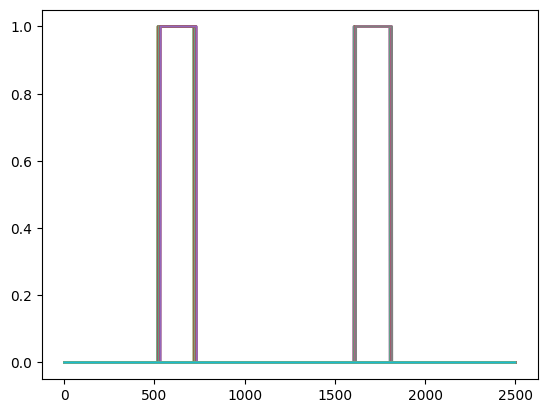

In [26]:
print(data["spikeBuffers"].shape)
plt.plot(data["spikeBuffers"][:,0,:]);

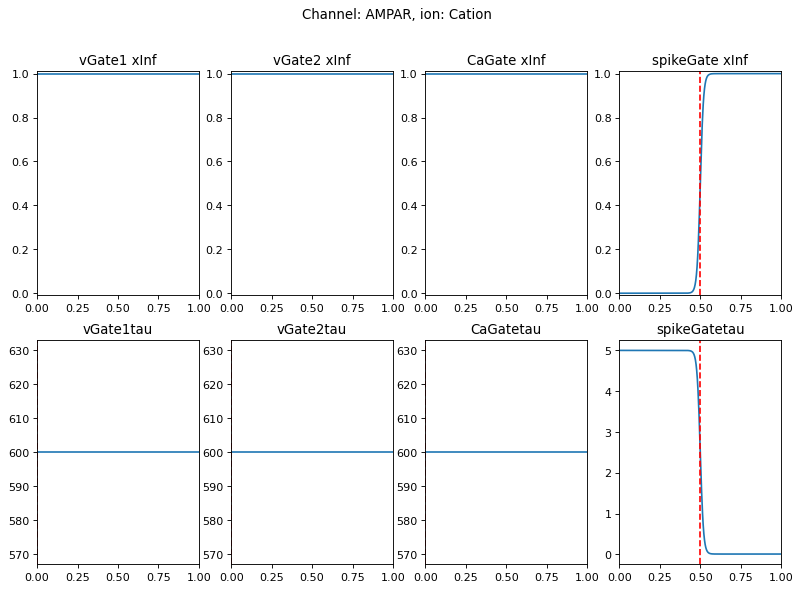

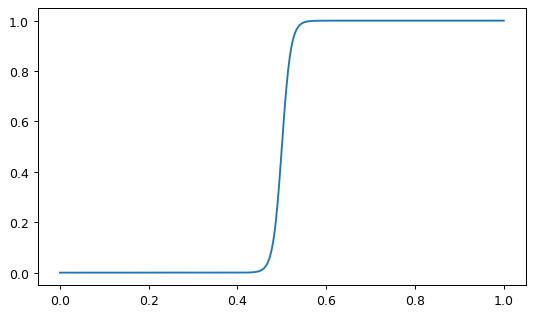

In [123]:
def examineGate(gateInfo,valRange,gateName,ax=None):
    gRange = [min(valRange),max(valRange)]
    vH,vK = gateInfo["vHalf"],gateInfo["vKi"]
    tau0,tau1,th,tkInv = gateInfo["tau0"],gateInfo["tau1"],gateInfo["th"],gateInfo["tkInv"]
    minOp = gateInfo["minOpenness"]
    

    xInf = sigmoid(valRange,vH,vK,minOp)
    tau = tau0 + tau1*sigmoid(valRange,th,tkInv,0)
    if ax == None:
        fig,ax = plt.subplots(2,1,figsize=(8,6), dpi=100)
    else:
        ax[0].plot(valRange,xInf)
        ax[0].axvline(vH,color="r",linestyle="--")
        ax[0].set_title(f"{gateName} xInf")
        ax[0].set_xlim(gRange)
        #x[0].set_ylabel("Gate opening")
        ax[0].set_ylim(-0.01,1.01)

        ax[1].plot(valRange,tau)
        ax[1].axvline(th,color="r",linestyle="--")
        ax[1].set_title(f"{gateName}tau")
        #ax[1].set_ylabel("Time constant (ms)")
        ax[1].set_xlim(gRange)
    
    return xInf

def examineChannel(channel,s0=-100,s1=100):
    fig,ax = plt.subplots(2,4,figsize=(12,8), dpi=80)
    fig.suptitle(f"Channel: {channel['name']}, ion: {channel['ion']}")
    valRange = np.linspace(s0,s1,501)
    netOpening = 1
    for i,(gate,gateData) in enumerate(channel["gates"].items()):
        exponent = gateData["exponent"]
        xInf = examineGate(gateData,valRange,gate,[ax[0,i],ax[1,i]])
        netOpening *= xInf**exponent

    fig,ax = plt.subplots(1,1,dpi=90,figsize=[7,4])
    ax.plot(valRange,netOpening)



amp = genAMPA(TS)

examineChannel(amp,0,1)

In [124]:
print(amp["gates"]["spikeGate"])

{'x': 0.0, 'vHalf': 0.5, 'vKi': 100, 'tau0': 0.01, 'tau1': 4.99, 'th': 0.5, 'tkInv': -100, 'exponent': 1, 'minOpenness': 0}


Text(0.5, 1.0, 'gating value')

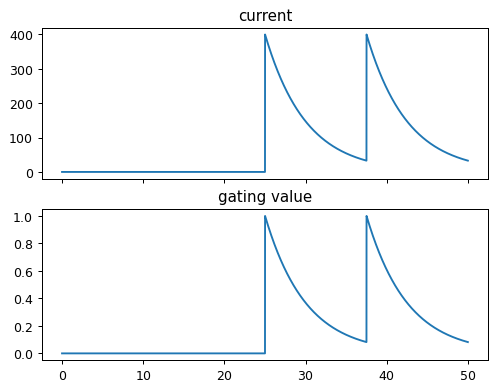

In [127]:
#need to be able to test this in a reduced simulation 
def temporalChannelTest(channel,duration,TS):
    channel = deepcopy(channel)
    nIterations = int(duration/TS)
    voltages = -80*np.ones(nIterations)
    inputs = np.zeros(nIterations)
    ind = int(nIterations/2)
    inputs[ind:(ind+1)] = 1
    ind = int(3*nIterations/4)
    inputs[ind:(ind+1)] = 1
    currents = np.zeros(nIterations)
    gatingTotals = np.zeros(nIterations)
    Erev = channel["Erev"]
    g = channel["conductance"]
    tv=np.linspace(0,duration,nIterations)
    for it in range(nIterations):
        gatingTotal = 1
        for gate,val in channel["gates"].items():
            gatingTotal *= (val["x"]**val["exponent"])

        V = voltages[it]
        I = -g*gatingTotal*(V-Erev) 
        currents[it]=I
        gatingTotals[it] = gatingTotal
        #update gates,
        #then update voltages
        gateDataMap = {"vGate1":V,"vGate2":V,"CaGate":0,"spikeGate":inputs[it]}
        for gate,val in channel["gates"].items():
            d = gateDataMap[gate]
            val["x"] = solveGate(val["x"],d,TS,val["vHalf"],val["vKi"],val["tau0"],val["tau1"],val["th"],val["tkInv"],val["minOpenness"])

    return currents,gatingTotals,tv


currents,gatingTotals,tv = temporalChannelTest(amp,50,0.01,)
fig,ax = plt.subplots(2,1,dpi=90,sharex=True)
ax[0].plot(tv,currents)
ax[0].set_title("current")
ax[1].plot(tv,gatingTotals)
ax[1].set_title("gating value")


In [56]:
nNeurons = 100
allChannelDataPy = genChannelData(nNeurons)
allChannelDataCpp = genChannelData(nNeurons)

nChannels is not a list or tuple
nChannels is not a list or tuple


In [57]:
import time
runTime = 15
t0 = time.time()
vDataPy,gateDataPy,netCurrentPy = solveSystemStandard(nNeurons,allChannelDataPy,TS,runTime)
t1 = time.time()
pyTime = t1-t0
print(f"Python time: {pyTime:.3f}")

ValueError: too many values to unpack (expected 3)

In [ ]:
#runTime = 100
t0 = time.time()
vDataCpp,gateDataCpp,netCurrentCpp = solveSystemCpp(nNeurons,allChannelDataCpp,TS,runTime)
t1 = time.time()
cppTime = t1-t0
print(f"Python time: {cppTime:.3f}")
speedUp = pyTime/cppTime
print(f"Speed up: {speedUp:.2f}x")

Python time: 0.227
Speed up: 31.52x


In [ ]:
netCurrentCpp[:,0]

array([1.65750000e+04, 2.90062500e+04, 5.07609375e+04, 8.88316406e+04,
       1.55455375e+05, 2.72046906e+05, 4.76082062e+05, 8.33143562e+05,
       1.45800112e+06, 2.55150200e+06, 4.46512850e+06, 7.81397450e+06,
       1.36744550e+07, 2.39302960e+07, 4.18780160e+07, 7.32865280e+07,
       1.28251416e+08, 2.24439968e+08, 3.92769984e+08, 6.87347456e+08,
       1.20285811e+09, 2.10500147e+09, 3.68375219e+09, 6.44656589e+09,
       1.12814920e+10, 1.97426094e+10, 3.45495675e+10, 6.04617359e+10,
       1.05808052e+11, 1.85164071e+11, 3.24037149e+11, 5.67064986e+11,
       9.92363741e+11, 1.73663663e+12, 3.03911430e+12, 5.31844982e+12,
       9.30728745e+12, 1.62877523e+13, 2.85035672e+13, 4.98812385e+13,
       8.72921652e+13, 1.52761283e+14, 2.67332270e+14, 4.67831494e+14,
       8.18705122e+14, 1.43273398e+15, 2.50728433e+15, 4.38774772e+15,
       7.67855864e+15, 1.34374784e+16, 2.35155859e+16, 4.11522721e+16,
       7.20164740e+16, 1.26028840e+17, 2.20550470e+17, 3.85963285e+17,
      

In [ ]:
netCurrentPy[:,0]

array([6.95000000e+02, 6.18549992e+02, 5.50509480e+02, 4.89953419e+02,
       4.36058563e+02, 3.88092136e+02, 3.45402012e+02, 3.07407776e+02,
       2.73592922e+02, 2.43497698e+02, 2.16712955e+02, 1.92874531e+02,
       1.71658333e+02, 1.52775917e+02, 1.35970562e+02, 1.21013807e+02,
       1.07702286e+02, 9.58550377e+01, 8.53109827e+01, 7.59267797e+01,
       6.75748339e+01, 6.01416073e+01, 5.35260353e+01, 4.76381731e+01,
       4.23979788e+01, 3.77342014e+01, 3.35834370e+01, 2.98892574e+01,
       2.66014347e+01, 2.36752796e+01, 2.10710020e+01, 1.87531967e+01,
       1.66903400e+01, 1.48544016e+01, 1.32204142e+01, 1.17661695e+01,
       1.04718933e+01, 9.31998253e+00, 8.29478550e+00, 7.38236046e+00,
       6.57030249e+00, 5.84757042e+00, 5.20433998e+00, 4.63186216e+00,
       4.12235832e+00, 3.66889954e+00, 3.26532269e+00, 2.90613604e+00,
       2.58646154e+00, 2.30195093e+00, 2.04873848e+00, 1.82337809e+00,
       1.62280655e+00, 1.44429636e+00, 1.28542423e+00, 1.14402914e+00,
      

In [ ]:
allChannelDataPy["conductance"].dtype

dtype('int32')

In [ ]:
allChannelDataCpp["conductance"].dtype

dtype('int32')

In [ ]:
gateDataCpp[:,:,1]

array([[9.9997169e-01, 8.7565914e-29, 9.9997169e-01, ..., 9.9997181e-01,
        2.3195435e-18, 9.9997181e-01],
       [9.9997169e-01, 8.7565914e-29, 9.9997169e-01, ..., 9.9997181e-01,
        2.3195435e-18, 9.9997181e-01],
       [9.9994349e-01, 5.1756003e-19, 9.9994349e-01, ..., 9.9994373e-01,
        9.8902117e-03, 9.9994373e-01],
       ...,
       [9.9984968e-01, 6.2260741e-01, 9.9984968e-01, ..., 9.9987793e-01,
        6.2649429e-01, 9.9987793e-01],
       [9.9984968e-01, 6.2638134e-01, 9.9984968e-01, ..., 9.9987793e-01,
        6.3022935e-01, 9.9987793e-01],
       [9.9984968e-01, 6.2638134e-01, 9.9984968e-01, ..., 9.9987793e-01,
        6.3022935e-01, 9.9987793e-01]], dtype=float32)

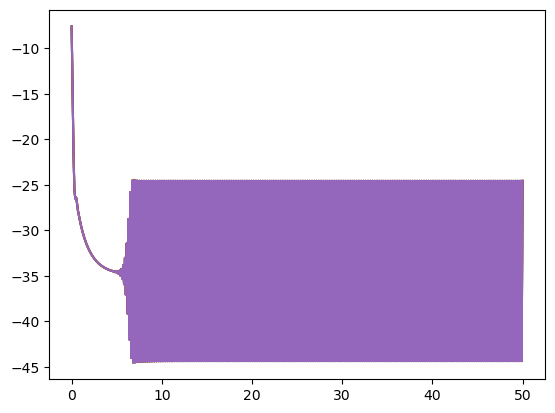

In [ ]:
#thought I could be clever about it, but its hard to beat the basic solver.
def solveSystemStrangSplit(nNeurons,ac,TS,runTime):
    voltage = np.zeros([nNeurons],dtype = np.float32)
    calciumVals = np.zeros([nNeurons],dtype = np.float32)
    spikeVals = np.zeros([nNeurons],dtype = np.float32)
    nIterations = int(runTime/TS)
    tv = np.linspace(0,runTime,nIterations)
    vOverTime = []
    nChannels = len(ac["neuronId"])
    for iteration,t in enumerate(tv):   
        #solve gates for a half step 
        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            Ca = calciumVals[neurId]
            spikes = spikeVals[neurId]
            xs = ac["x"][i]
            xhs,xks = ac["vHalf"][i],ac["vKi"][i]
            xts0,xts1 = ac["tau0"][i],ac["tau1"][i]
            xths,xtks = ac["th"][i],ac["tkInv"][i]
            tempTS = TS/2
            xs[0] = solveGate(xs[0],V,tempTS,xhs[0],xks[0],xts0[0],xts1[0],xths[0],xtks[0]) #gate1
            xs[1] = solveGate(xs[1],V,tempTS,xhs[1],xks[1],xts1[1],xts1[1],xths[1],xtks[1]) #gate2
            xs[2] = solveGate(xs[2],Ca,tempTS,xhs[2],xks[2],xts0[2],xts1[2],xths[2],xtks[2]) #CaGate
            xs[3] = solveGate(xs[3],spikes,tempTS,xhs[3],xks[3],xts0[3],xts1[3],xths[3],xtks[3]) #spikeGate
        

        #calculate currents
        netCurrent = np.zeros([nNeurons])
        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            xs = ac["x"][i]
            Erev = ac["Erev"][i]
            g = ac["conductance"][i]

            gatingTotal = 1
            for x in xs: gatingTotal*=x #can unroll this for performance, but this is neater code
            I = -g*gatingTotal*(V-Erev) # -g*gatingTotal*
            #ac["current"][i] = I
            netCurrent[neurId] += I


        #calculate the voltage
        for i in range(nNeurons):
            voltage[i] = voltage[i] + TS*netCurrent[i] #assume membrane capacitance is 1

        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            Ca = calciumVals[neurId]
            spikes = spikeVals[neurId]
            xs = ac["x"][i]
            xhs,xks = ac["vHalf"][i],ac["vKi"][i]
            xts0,xts1 = ac["tau0"][i],ac["tau1"][i]
            xths,xtks = ac["th"][i],ac["tkInv"][i]
            tempTS = TS/2
            xs[0] = solveGate(xs[0],V,tempTS,xhs[0],xks[0],xts0[0],xts1[0],xths[0],xtks[0]) #gate1
            xs[1] = solveGate(xs[1],V,tempTS,xhs[1],xks[1],xts1[1],xts1[1],xths[1],xtks[1]) #gate2
            xs[2] = solveGate(xs[2],Ca,tempTS,xhs[2],xks[2],xts0[2],xts1[2],xths[2],xtks[2]) #CaGate
            xs[3] = solveGate(xs[3],spikes,tempTS,xhs[3],xks[3],xts0[3],xts1[3],xths[3],xtks[3]) #spikeGate


        vOverTime.append(voltage.copy())
        
    return np.array(vOverTime)

TS = 0.1
runTime = 50
vData = solveSystemStrangSplit(nNeurons,deepcopy(allChannelData),TS,runTime)

tv = np.linspace(0,runTime,len(vData))
plt.plot(tv,vData);

In [ ]:
def solveSystemStandard(nNeurons,ac,TS,runTime):
    voltage = -70*np.ones([nNeurons],dtype = np.float32)
    calciumVals = np.zeros([nNeurons],dtype = np.float32)
    spikeVals = np.zeros([nNeurons],dtype = np.float32)
    nIterations = int(runTime/TS)
    tv = np.linspace(0,runTime,nIterations)
    vOverTime = []
    nChannels = len(ac["neuronId"])
    for iteration,t in enumerate(tv):   
        #calculate currents
        netCurrent = np.zeros([nNeurons])
        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            xs = ac["x"][i]
            Erev = ac["Erev"][i]
            g = ac["conductance"][i]

            gatingTotal = 1
            for x in xs: gatingTotal*=x #can unroll this for performance, but this is neater code
            I = -g*gatingTotal*(V-Erev) # -g*gatingTotal*
            netCurrent[neurId] += I
            voltage[neurId] += TS*I #cm = 1

        #update the gates
        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            Ca = calciumVals[neurId]
            spikes = spikeVals[neurId]
            xs = ac["x"][i]
            xhs,xks = ac["vHalf"][i],ac["vKi"][i]
            xts0,xts1 = ac["tau0"][i],ac["tau1"][i]
            xths,xtks = ac["th"][i],ac["tkInv"][i]
            tempTS = TS
            xs[0] = solveGate(xs[0],V,tempTS,xhs[0],xks[0],xts0[0],xts1[0],xths[0],xtks[0]) #gate1
            xs[1] = solveGate(xs[1],V,tempTS,xhs[1],xks[1],xts1[1],xts1[1],xths[1],xtks[1]) #gate2
            xs[2] = solveGate(xs[2],Ca,tempTS,xhs[2],xks[2],xts0[2],xts1[2],xths[2],xtks[2]) #CaGate
            xs[3] = solveGate(xs[3],spikes,tempTS,xhs[3],xks[3],xts0[3],xts1[3],xths[3],xtks[3]) #spikeGate

        vOverTime.append(voltage.copy())
    return np.array(vOverTime)

In [ ]:


#calculate currents
#I = g*vGate1*vGate2*CaGate*spikeGate*(V-Erev)

voltage = np.zeros([nNeurons])
calciumVals = np.zeros([nNeurons])
spikeVals = np.zeros([nNeurons])


ac = allChannelData
nChannels = ac["nChannels"]

# netGating = ac["x"][0][0]*ac["x"][0][1]*ac["x"][0][2]*ac["x"][0][3]
# neurId = 0
# I = ac["conductance"][0]*netGating*(V[neurId]-ac["Erev"][0])

#dont forget that cool solving method 

#solve gates -> calculate currents -> calculate voltage
#going to do it with plain euler first
#then semi-implicit euler
#then strang splitting

#TS>0.17 = unstable
TS = 0.05
runTime = 20

nIterations = int(runTime/TS)
tv = np.linspace(0,runTime,nIterations)
vOverTime = []

def solveSystemStandard():
    for iteration,t in enumerate(tv):   
        #calculate currents
        netCurrent = np.zeros([nNeurons])
        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            xs = ac["x"][i]
            Erev = ac["Erev"][i]
            g = ac["conductance"][i]

            gatingTotal = 1
            for x in xs: gatingTotal*=x #can unroll this for performance, but this is neater code
            I = -g*gatingTotal*(V-Erev) # -g*gatingTotal*
            # if i == 0:
            #     print((V-Erev))
            #ac["current"][i] = I
            netCurrent[neurId] += I


        #calculate the voltage
        for i in range(nNeurons):
            voltage[i] = voltage[i] + TS*netCurrent[i]

        #update the gates
        for i in range(nChannels):
            neurId = ac["neuronId"][i]
            V = voltage[neurId]
            Ca = calciumVals[neurId]
            spikes = spikeVals[neurId]
            xs = ac["x"][i]
            xhs,xks = ac["vHalf"][i],ac["vKi"][i]
            xts0,xts1 = ac["tau0"][i],ac["tau1"][i]
            xths,xtks = ac["th"][i],ac["tkInv"][i]
            xDot = [0.0 for _ in range(4)]
            #gate1
            xs[0] = solveGate(xs[0],V,TS,xhs[0],xks[0],xts0[0],xts1[0],xths[0],xtks[0])
            #gate2
            xs[1] = solveGate(xs[1],V,TS,xhs[1],xks[1],xts1[1],xts1[1],xths[1],xtks[1])
            #CaGate
            xs[2] = solveGate(xs[2],Ca,TS,xhs[2],xks[2],xts0[2],xts1[2],xths[2],xtks[2])
            #spikeGate
            xs[3] = solveGate(xs[3],spikes,TS,xhs[3],xks[3],xts0[3],xts1[3],xths[3],xtks[3])

        
        vOverTime.append(voltage.copy())
    return np.array(vOverTime)
# plt.plot(tv,vOverTime);

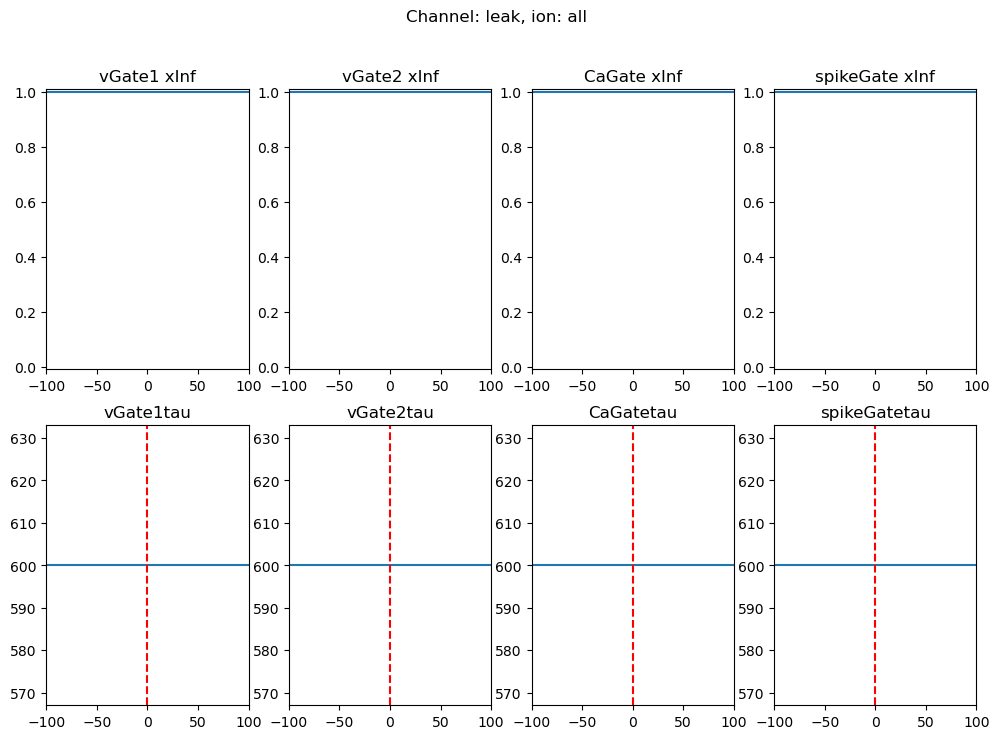

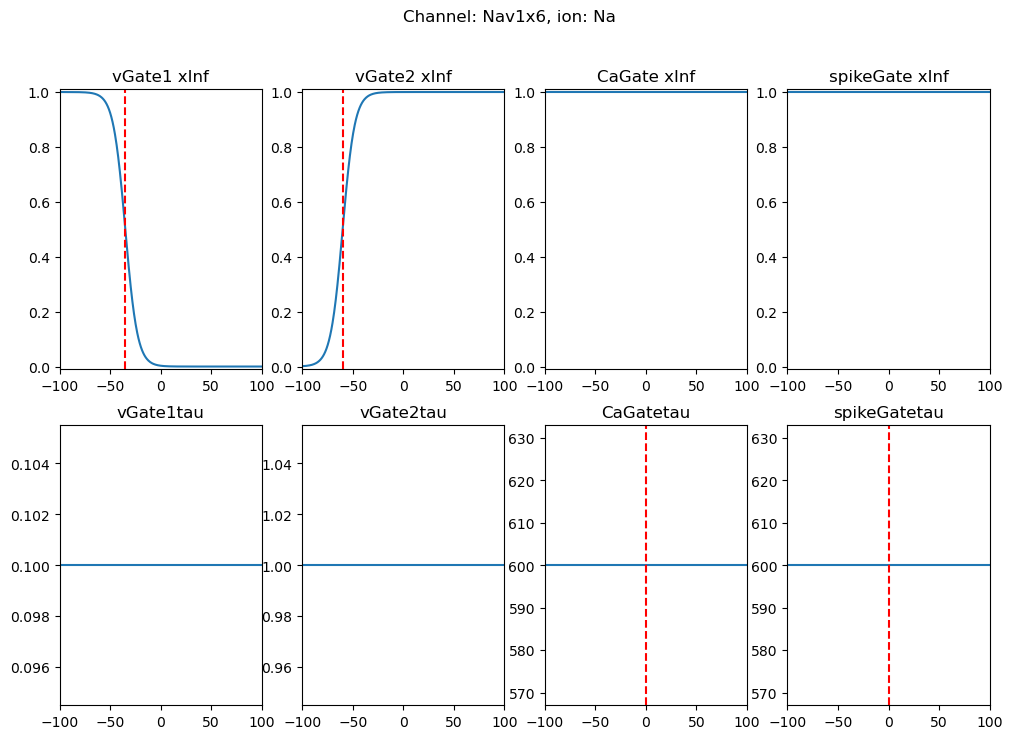

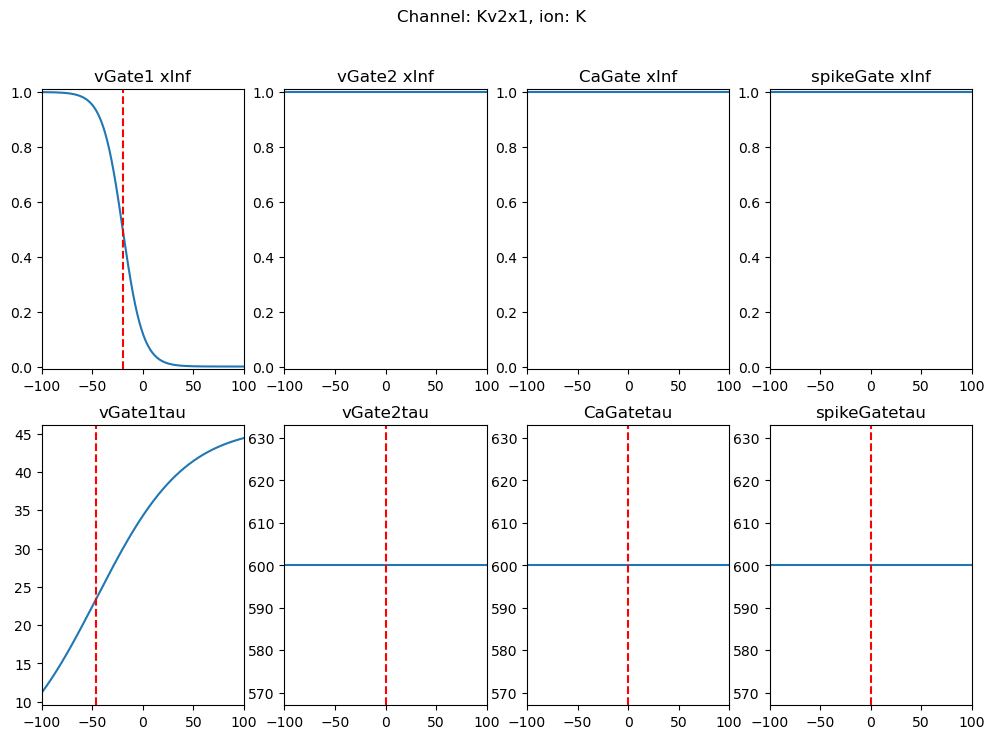

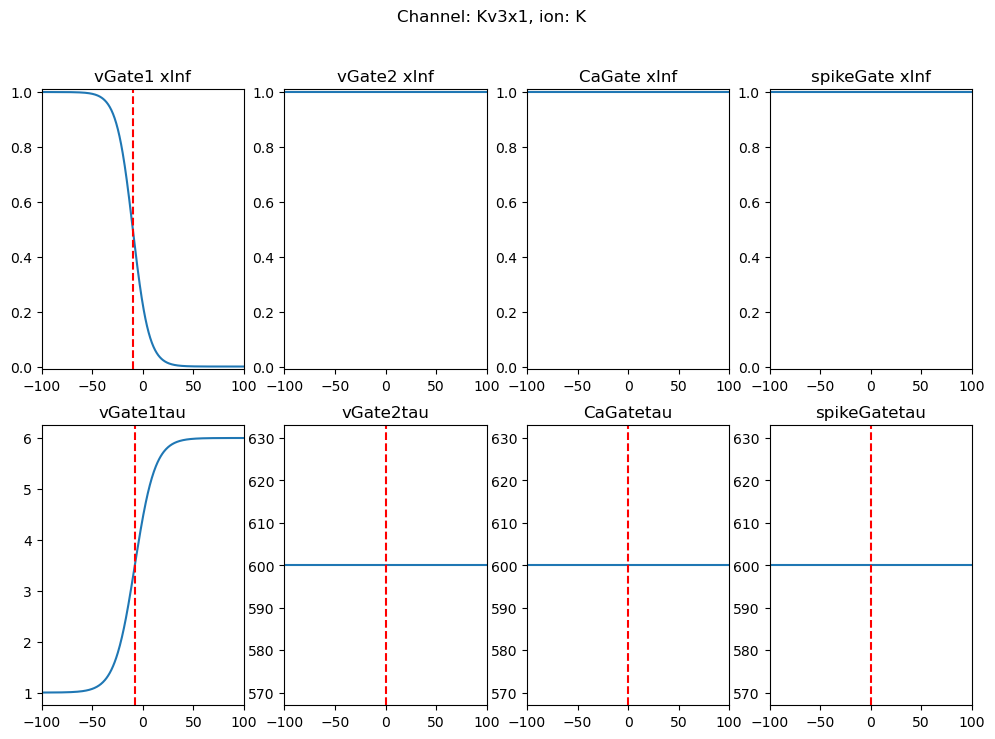

In [ ]:

def examineGate(gateInfo,gRange,gateName,ax=None):
    sps = np.linspace(gRange[0],gRange[1],501)
    vH,vK = gateInfo["vHalf"],gateInfo["vKi"]
    tau0,tau1,th,tkInv = gateInfo["tau0"],gateInfo["tau1"],gateInfo["th"],gateInfo["tkInv"]

    xInf = sigmoid(sps,vH,vK)
    tau = tau0 + tau1*sigmoid(sps,th,tkInv)
    if ax == None:
        fig,ax = plt.subplots(2,1,figsize=(8,6), dpi=100)
    else:
        ax[0].plot(sps,xInf)
        ax[0].axvline(vH,color="r",linestyle="--")
        ax[0].set_title(f"{gateName} xInf")
        ax[0].set_xlim(gRange)
        #x[0].set_ylabel("Gate opening")
        ax[0].set_ylim(-0.01,1.01)

        ax[1].plot(sps,tau)
        ax[1].axvline(th,color="r",linestyle="--")
        ax[1].set_title(f"{gateName}tau")
        #ax[1].set_ylabel("Time constant (ms)")
        ax[1].set_xlim(gRange)
        

def examineChannel(channel):
    fig,ax = plt.subplots(2,4,figsize=(12,8), dpi=100)
    fig.suptitle(f"Channel: {channel['name']}, ion: {channel['ion']}")
    for i,(gate,gateData) in enumerate(channel["gates"].items()):
        examineGate(gateData,[-100,100],gate,[ax[0,i],ax[1,i]])

examineChannel(leakChannel)
examineChannel(Nav1x6)
examineChannel(Kv2x1)
examineChannel(Kv3x1)

In [ ]:

def solveGate(x,s,TS,xh,xk,xt0,xt1,xth,xtk):
    xInf = sigmoid(s,xh,xk)#*(xt0+xt1)/TS
    tau = xt0 + xt1*sigmoid(s,xth,xtk)
    return (tau*x + TS*xInf)/(tau+TS)





def runGateSim(xt0,xt1,TS):
    #TS = 0.02
    x = 0
    xh = 0.5
    xk = 100.0
    xt0 = TS/1000
    xt1 = xt1-xt0
    xth = 0.5
    xtk = -100.0
    runTime = 40
    
    nIterations = int(runTime/TS)
    tv = np.linspace(0,runTime,nIterations)
    xOverTime = []
    for i in range(nIterations):
        s = 0
        if i == int(5/TS):
            s = 1
        x = solveGate(x,s,TS,xh,xk,xt0,xt1,xth,xtk)
        xOverTime.append(x)

    fig,ax = plt.subplots(1,1,figsize=(8,6), dpi=100, sharex=True)
    ax.plot(tv,xOverTime)

from ipywidgets import interact
interact(runGateSim,xt0=(0.01,1.0,0.01),xt1=(0.1,10.0,0.1),TS=(0.01,0.1,0.01))

interactive(children=(FloatSlider(value=0.5, description='xt0', max=1.0, min=0.01, step=0.01), FloatSlider(val…

<function __main__.runGateSim(xt0, xt1, TS)>

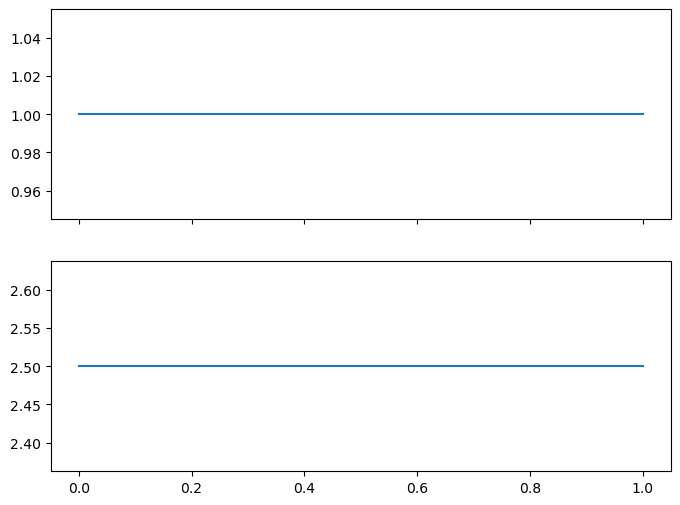

In [ ]:
#test the gates quickly
TS = 0.02
xh = -0.5
xk = 100.0
xt0 = TS/1000
xt1 = 5
xth = -0.5
xtk = 0

sps = np.linspace(0,1,100)
xInf = sigmoid(sps,xh,xk)
tau = xt0 + xt1*sigmoid(sps,xth,xtk)

fig,ax = plt.subplots(2,1,figsize=(8,6), dpi=100, sharex=True)
ax[0].plot(sps,xInf)
ax[1].plot(sps,tau)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])